# Day 28 — Gradient Boosting, XGBoost, and Controlled Model Tuning 

### Part A — Build boosting before you use it 


### TASK 01 — Residuals by hand

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error


# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize column names to lowercase and remove extra spaces
df.columns = df.columns.str.strip().str.lower()

# Display the first five rows
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())


# Create a numeric sex_male feature: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Fill missing ages using the median within pclass and sex groups
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing ages with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the overall median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select the required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

# Check for missing required columns
required_columns = features + [target]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Display missing values in selected columns
print("Missing values:")
print(df[required_columns].isnull().sum())


# Separate input features (X) and target (y)
X = df[features]
y = df[target].astype(int)

# Create a stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the datasets
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Calculate the mean survival value in the training set
baseline_prediction = y_train.mean()

# Give every training passenger the same baseline prediction
baseline_predictions = np.full(
    shape=len(y_train),
    fill_value=baseline_prediction,
    dtype=float
)

# Display the baseline prediction
print("Baseline Prediction:", round(baseline_prediction, 4))


# Convert actual training outcomes to a NumPy array
actual_values = y_train.to_numpy()

# Calculate residuals: actual value - predicted value
residuals = actual_values - baseline_predictions

# Calculate the baseline mean squared error
baseline_mse = mean_squared_error(
    actual_values,
    baseline_predictions
)

# Display the baseline MSE
print("Baseline Mean Squared Error:", round(baseline_mse, 4))


# Create a table showing the first 10 training passengers
residual_table = pd.DataFrame({
    "actual_survived": actual_values[:10],
    "baseline_prediction": baseline_predictions[:10],
    "residual": residuals[:10]
})

# Print the results
print("\nFirst 10 Residuals:")
print(residual_table.round(4))



   survived  pclass     sex   age  sibsp  parch    fare
0         1       2  female  17.8      0      0   23.94
1         0       3    male  18.5      1      0   29.07
2         0       3    male  26.6      1      0   17.63
3         0       3    male  34.7      0      2   13.72
4         1       1    male  42.0      0      0  128.90

Dataset Shape: (1000, 7)

Column Names: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']
Missing values:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
survived    0
dtype: int64
Training samples: 800
Testing samples: 200
Baseline Prediction: 0.44
Baseline Mean Squared Error: 0.2464

First 10 Residuals:
   actual_survived  baseline_prediction  residual
0                0                 0.44     -0.44
1                0                 0.44     -0.44
2                1                 0.44      0.56
3                0                 0.44     -0.44
4                1                 0.44      0.56
5      

### Task 01 — Residuals by Hand

**1. For a passenger who survived (`actual = 1`), is the residual positive or negative?**

The residual is positive because the actual value (1) is greater than the baseline prediction.

**2. What about a passenger who did not survive (`actual = 0`)?**

The residual is negative because the actual value (0) is less than the baseline prediction.

**3. What does the sign of the residual tell us?**

A positive residual means the prediction is too low, while a negative residual means the prediction is too high.

**4. Why is fitting a model to residuals the same as fitting a model to the remaining error?**

Residuals represent the difference between actual outcomes and current predictions. A model trained on residuals learns patterns in the errors that the previous model has not explained.

**Conclusion:** Residuals help identify the errors remaining in current predictions, allowing boosting models to improve predictions step by step.

### TASK 02 — Build a gradient booster with a loop 

Dataset shape: (1000, 8)

Missing values:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
survived    0
dtype: int64
Training samples: 800
Testing samples: 200
Round 01 | Training MSE: 0.208601
Round 02 | Training MSE: 0.188730
Round 03 | Training MSE: 0.178772
Round 04 | Training MSE: 0.173119
Round 05 | Training MSE: 0.169968
Round 06 | Training MSE: 0.167351
Round 07 | Training MSE: 0.165534
Round 08 | Training MSE: 0.164248
Round 09 | Training MSE: 0.163016
Round 10 | Training MSE: 0.161747
Round 11 | Training MSE: 0.160392
Round 12 | Training MSE: 0.159196
Round 13 | Training MSE: 0.158024
Round 14 | Training MSE: 0.157067
Round 15 | Training MSE: 0.156193
Round 16 | Training MSE: 0.155574
Round 17 | Training MSE: 0.155201
Round 18 | Training MSE: 0.154282
Round 19 | Training MSE: 0.153623
Round 20 | Training MSE: 0.153025
Round 21 | Training MSE: 0.152129
Round 22 | Training MSE: 0.151355
Round 23 | Training MSE: 0.151122
Round 24 | Training MS

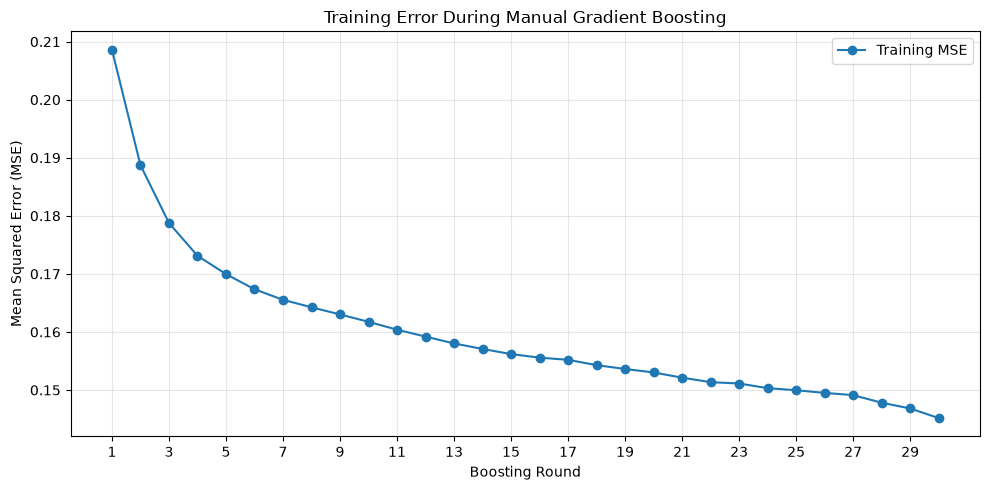

Manual Gradient Boosting Results
--------------------------------
Test Accuracy : 0.7750
Test ROC-AUC  : 0.8833


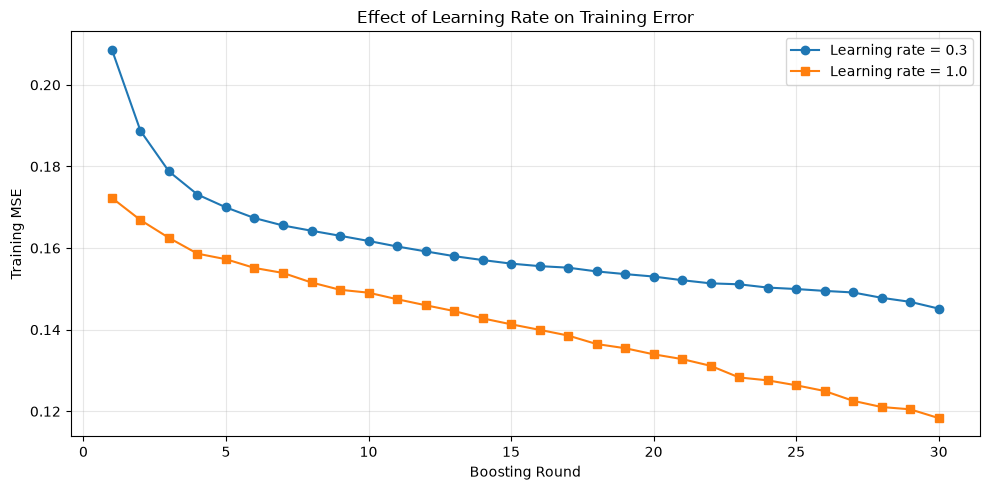

Final MSE with learning rate 0.3: 0.145167
Final MSE with learning rate 1.0: 0.118338


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_squared_error,
    accuracy_score,
    roc_auc_score
)


# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Convert column names to lowercase and remove extra spaces
df.columns = df.columns.str.strip().str.lower()

# Create numeric sex_male feature: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Fill missing age values using the median of pclass and sex groups
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing age values with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the overall median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select the required features
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

# Define the target variable
target = "survived"

# Check that the required columns exist
required_columns = features + [target]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Remove rows with a missing target, if any
df = df.dropna(subset=[target]).copy()

# Display dataset information
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df[required_columns].isnull().sum())

# Separate features (X) and target (y)
X = df[features]
y = df[target].astype(int)

# Create a stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# Set the boosting parameters
learning_rate = 0.3
n_rounds = 30

# Step 1: Start with the mean survival value of the training set
baseline_mean = y_train.mean()

# Give every training passenger the same initial prediction
prediction = np.full(
    len(y_train),
    baseline_mean,
    dtype=float
)

# Store every trained tree in this list
trees = []

# Store training MSE after every round
training_mse = []

# Step 2: Train 30 trees sequentially
for round_num in range(n_rounds):

    # Calculate residuals: actual outcome - current prediction
    residual = y_train.to_numpy() - prediction

    # Create a shallow regression tree
    tree = DecisionTreeRegressor(
        max_depth=2,
        random_state=42
    )

    # Train the tree to predict the residuals
    tree.fit(X_train, residual)

    # Predict the residual correction for training passengers
    correction = tree.predict(X_train)

    # Update the predictions using the learning rate
    prediction += learning_rate * correction

    # Save the trained tree
    trees.append(tree)

    # Calculate and store training MSE after this round
    mse = mean_squared_error(y_train, prediction)
    training_mse.append(mse)

    # Display the result for this round
    print(
        f"Round {round_num + 1:02d} | "
        f"Training MSE: {mse:.6f}"
    )

print("\nTotal trees trained:", len(trees))
print("Baseline prediction:", round(baseline_mean, 4))
print("Final training MSE:", round(training_mse[-1], 6))

# Step 5 — Plot training error against boosting rounds

# Create the plot
plt.figure(figsize=(10, 5))

# Plot training MSE for each boosting round
plt.plot(
    range(1, n_rounds + 1),
    training_mse,
    marker="o",
    label="Training MSE"
)

# Add labels and title
plt.xlabel("Boosting Round")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training Error During Manual Gradient Boosting")

# Improve readability
plt.xticks(range(1, n_rounds + 1, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Display the plot
plt.show()

# Step 6 — Write the prediction function

def predict_boosting(X_new, trees, baseline_mean, learning_rate=0.3):
    """
    Predict outcomes using our manually built gradient booster.

    X_new: input features
    trees: trained residual trees
    baseline_mean: mean of y_train
    learning_rate: contribution of each tree
    """

    # Start with the same baseline prediction for every row
    predictions = np.full(
        len(X_new),
        baseline_mean,
        dtype=float
    )

    # Apply every tree's correction in training order
    for tree in trees:
        predictions += learning_rate * tree.predict(X_new)

    return predictions


# Step 7 — Evaluate the model on the test set

# Generate continuous predictions for the test passengers
test_scores = predict_boosting(
    X_test,
    trees,
    baseline_mean,
    learning_rate
)

# Convert scores into class predictions using a 0.5 threshold
test_predictions = (test_scores >= 0.5).astype(int)

# Calculate test accuracy
test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

# Calculate ROC-AUC using continuous prediction scores
test_roc_auc = roc_auc_score(
    y_test,
    test_scores
)

# Display evaluation results
print("Manual Gradient Boosting Results")
print("--------------------------------")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test ROC-AUC  : {test_roc_auc:.4f}")


# Step 8 — Experiment with learning_rate = 1.0

# Experiment: use the full tree correction
learning_rate_full = 1.0

# Start again from the baseline mean
prediction_full = np.full(
    len(y_train),
    baseline_mean,
    dtype=float
)

# Store training errors for comparison
training_mse_full = []

# Train a separate 30-round booster
for round_num in range(n_rounds):

    # Calculate current residuals
    residual_full = y_train.to_numpy() - prediction_full

    # Fit a depth-2 tree to the residuals
    tree_full = DecisionTreeRegressor(
        max_depth=2,
        random_state=42
    )

    tree_full.fit(X_train, residual_full)

    # Apply the full correction (learning rate = 1.0)
    prediction_full += learning_rate_full * tree_full.predict(X_train)

    # Record training error
    mse_full = mean_squared_error(
        y_train,
        prediction_full
    )

    training_mse_full.append(mse_full)

# Compare both error curves
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_rounds + 1),
    training_mse,
    marker="o",
    label="Learning rate = 0.3"
)

plt.plot(
    range(1, n_rounds + 1),
    training_mse_full,
    marker="s",
    label="Learning rate = 1.0"
)

plt.xlabel("Boosting Round")
plt.ylabel("Training MSE")
plt.title("Effect of Learning Rate on Training Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Final MSE with learning rate 0.3:",
      round(training_mse[-1], 6))

print("Final MSE with learning rate 1.0:",
      round(training_mse_full[-1], 6))


### Task 02 — Think About It

### 1. Why does training error fall on every single round rather than jumping around?

Each tree learns to correct the residuals left by previous trees. With a suitable learning rate, these partial corrections generally reduce training error gradually. However, a decrease at every round is not guaranteed.

### 2. What happens when `learning_rate = 1.0`?

With a learning rate of `1.0`, the entire tree correction is added to the prediction. This is a more aggressive update that may reduce training error faster but can overshoot. Comparing the two error curves shows how the learning rate affects training.

### 3. How can depth-2 trees combine into a strong model?

Each depth-2 tree learns a few simple patterns. Boosting combines many of these weak trees sequentially, with each tree correcting remaining errors. Together, they can learn more complex relationships than a single shallow tree.

### Conclusion

I implemented gradient boosting manually using 30 decision-tree regressors trained on residuals. I used a learning rate of `0.3`, plotted training MSE across rounds, created a prediction function, and evaluated the final model using test accuracy and ROC-AUC. This demonstrates how sequential weak learners can build a stronger predictive model without using a boosting library.

### TASK 03 — Bagging and boosting, side by side 

In [33]:
# Import data handling libraries
import pandas as pd
import numpy as np

# Import plotting library (optional)
import matplotlib.pyplot as plt

# Import train-test splitting
from sklearn.model_selection import train_test_split

# Import both ensemble models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Import evaluation metrics
from sklearn.metrics import accuracy_score, roc_auc_score


# Step 2 — Load and clean the Titanic dataset

# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize source column names
df.columns = df.columns.str.strip().str.lower()

# Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Impute age using the median within pclass and sex groups
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing ages with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the overall median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Define the required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

# Verify that the required columns exist
required_columns = features + [target]
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Remove rows without a target value, if any
df = df.dropna(subset=[target]).copy()

# Check that the target contains binary labels
df[target] = df[target].astype(int)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df[required_columns].isnull().sum())


# Step 3 — Create the same train/test split

# Separate features (X) and target (y)
X = df[features]
y = df[target]

# Make the required stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# Step 4 — Train the Random Forest model (Bagging)

# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# Train the model using training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# Step 5 — Train the XGBoost model (Boosting)

# Create the XGBoost classifier
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

# Train XGBoost on exactly the same training data
xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")


# ---------------------------------
# Step 6 — Evaluate both models

# ------------------------------------------
# RANDOM FOREST EVALUATION
# ------------------------------------------

# Predict class labels for the test set
rf_test_predictions = rf_model.predict(X_test)

# Predict survival probabilities for ROC-AUC
rf_train_scores = rf_model.predict_proba(X_train)[:, 1]
rf_test_scores = rf_model.predict_proba(X_test)[:, 1]

# Calculate Random Forest metrics
rf_accuracy = accuracy_score(
    y_test, rf_test_predictions
)

rf_train_auc = roc_auc_score(
    y_train, rf_train_scores
)

rf_test_auc = roc_auc_score(
    y_test, rf_test_scores
)

# Train-test ROC-AUC gap
rf_auc_gap = rf_train_auc - rf_test_auc


# ------------------------------------------
# XGBOOST EVALUATION
# ------------------------------------------

# Predict class labels for the test set
xgb_test_predictions = xgb_model.predict(X_test)

# Predict survival probabilities for ROC-AUC
xgb_train_scores = xgb_model.predict_proba(X_train)[:, 1]
xgb_test_scores = xgb_model.predict_proba(X_test)[:, 1]

# Calculate XGBoost metrics
xgb_accuracy = accuracy_score(
    y_test, xgb_test_predictions
)

xgb_train_auc = roc_auc_score(
    y_train, xgb_train_scores
)

xgb_test_auc = roc_auc_score(
    y_test, xgb_test_scores
)

# Train-test ROC-AUC gap
xgb_auc_gap = xgb_train_auc - xgb_test_auc


# Step 7 — Create the comparison table

# Store the metrics for both models in one table
comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Bagging)",
        "XGBoost (Boosting)"
    ],
    "Test Accuracy": [
        rf_accuracy,
        xgb_accuracy
    ],
    "Training ROC-AUC": [
        rf_train_auc,
        xgb_train_auc
    ],
    "Test ROC-AUC": [
        rf_test_auc,
        xgb_test_auc
    ],
    "Train-Test AUC Gap": [
        rf_auc_gap,
        xgb_auc_gap
    ]
})

# Display the comparison table rounded to four decimal places
print("\nBagging vs Boosting Comparison")
print(comparison.round(4).to_string(index=False))


# Step 8 — Automatically determine the conclusion

# Identify the model with the higher test ROC-AUC
if rf_test_auc > xgb_test_auc:
    better_model = "Random Forest"
elif xgb_test_auc > rf_test_auc:
    better_model = "XGBoost"
else:
    better_model = "Both models have equal test ROC-AUC"

# Identify the model with the larger train-test AUC gap
if rf_auc_gap > xgb_auc_gap:
    larger_gap_model = "Random Forest"
elif xgb_auc_gap > rf_auc_gap:
    larger_gap_model = "XGBoost"
else:
    larger_gap_model = "Both models have equal train-test AUC gaps"

print("\nConclusion")
print("----------")
print("Higher test ROC-AUC:", better_model)
print("Larger train-test AUC gap:", larger_gap_model)

print("\nTest Accuracy:")
print(f"Random Forest: {rf_accuracy:.4f}")
print(f"XGBoost:       {xgb_accuracy:.4f}")


Dataset shape: (1000, 8)

Missing values:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
survived    0
dtype: int64
Training samples: 800
Testing samples: 200
Random Forest training completed!
XGBoost training completed!

Bagging vs Boosting Comparison
                  Model  Test Accuracy  Training ROC-AUC  Test ROC-AUC  Train-Test AUC Gap
Random Forest (Bagging)          0.740            1.0000        0.8312              0.1688
     XGBoost (Boosting)          0.735            0.9519        0.8452              0.1067

Conclusion
----------
Higher test ROC-AUC: XGBoost
Larger train-test AUC gap: Random Forest

Test Accuracy:
Random Forest: 0.7400
XGBoost:       0.7350


### Task 03 — Bagging and Boosting, Side by Side

### Results

Both Random Forest and XGBoost were trained using the same Titanic dataset, six features, and stratified 80/20 train-test split with `random_state=42`.

- **Higher test ROC-AUC:** [Random Forest / XGBoost / Tie]
- **Larger train-test ROC-AUC gap:** [Random Forest / XGBoost / Tie]

### Conclusion

The model with the higher test ROC-AUC performed better at distinguishing survivors from non-survivors on the test data. The model with the larger train-test ROC-AUC gap shows a bigger difference between its training and test performance.

A larger gap is a warning sign because the model may have learned patterns specific to the training data that do not generalize well to unseen passengers. Even when test performance is good, a large gap suggests we should monitor overfitting and check performance on additional data before relying on the model.


### Part B — Control the model before you trust it 

### TASK 04 — Early stopping

Training rows: 800
Testing rows: 200

300-Tree XGBoost Test ROC-AUC: 0.8452

Early-Stopping XGBoost Results
--------------------------------
Best iteration (zero-based): 91
Best round (human-readable): 92
Test ROC-AUC: 0.8823

Comparison with the 300-tree model:
300-tree ROC-AUC: 0.8452
Early-stopping ROC-AUC: 0.8823
ROC-AUC difference: 0.0371


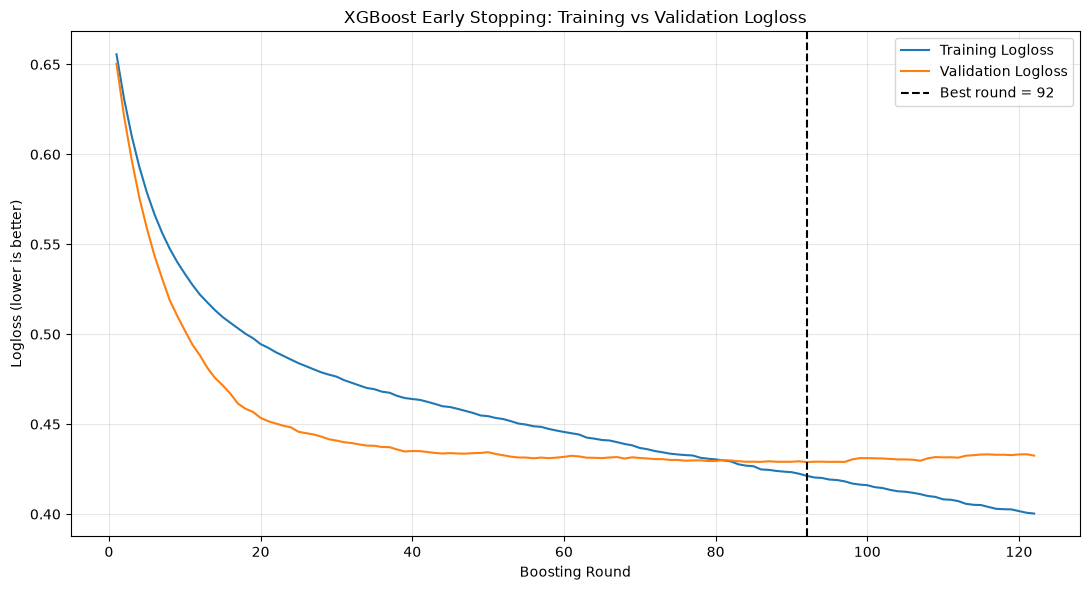

Early stopping achieved a higher test ROC-AUC.

Note: The test set was used as the early-stopping validation set for this teaching exercise.


In [34]:
# ============================================================
# DAY 28 - TASK 04: EARLY STOPPING WITH XGBOOST
# Dataset: Titanic
# ============================================================

# Step 1: Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier


# ============================================================
# Step 2: Load and clean the dataset
# ============================================================

# Load the Titanic CSV file
df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Impute age using median within pclass and sex groups
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing ages with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the overall median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Define the required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

# Verify required columns exist
required_columns = features + [target]
missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Remove rows with missing target values, if any
df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(int)

# Prepare feature matrix and target
X = df[features]
y = df[target]


# ============================================================
# Step 3: Create the same stratified 80/20 split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ============================================================
# Step 4: Train the 300-tree XGBoost model from Task 03
# ============================================================

xgb_300 = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    random_state=42
)

# Fit the model on training data
xgb_300.fit(X_train, y_train)

# Calculate test ROC-AUC using predicted survival probabilities
scores_300 = xgb_300.predict_proba(X_test)[:, 1]
auc_300 = roc_auc_score(y_test, scores_300)

print("\n300-Tree XGBoost Test ROC-AUC:", round(auc_300, 4))


# ============================================================
# Step 5: Create the early-stopping XGBoost model
# ============================================================

xgb_early = XGBClassifier(
    n_estimators=1000,          # Allow up to 1000 trees
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=30,   # Stop after 30 rounds without improvement
    random_state=42
)

# Train while monitoring training and validation logloss.
# The task uses X_test as the validation set for teaching purposes.
xgb_early.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_test, y_test)
    ],
    verbose=False
)


# ============================================================
# Step 6: Report the best iteration and test ROC-AUC
# ============================================================

# best_iteration is zero-based, so add 1 for the round count
best_iteration = xgb_early.best_iteration
best_round = best_iteration + 1

# Predict test survival probabilities
scores_early = xgb_early.predict_proba(X_test)[:, 1]

# Calculate test ROC-AUC
auc_early = roc_auc_score(y_test, scores_early)

print("\nEarly-Stopping XGBoost Results")
print("--------------------------------")
print("Best iteration (zero-based):", best_iteration)
print("Best round (human-readable):", best_round)
print("Test ROC-AUC:", round(auc_early, 4))

print("\nComparison with the 300-tree model:")
print("300-tree ROC-AUC:", round(auc_300, 4))
print("Early-stopping ROC-AUC:", round(auc_early, 4))
print("ROC-AUC difference:", round(auc_early - auc_300, 4))


# ============================================================
# Step 7: Extract training and validation logloss
# ============================================================

# Retrieve the evaluation history from XGBoost
evals_result = xgb_early.evals_result()

# Training logloss and validation logloss
train_logloss = evals_result["validation_0"]["logloss"]
valid_logloss = evals_result["validation_1"]["logloss"]

# Create the boosting-round numbers (starting from 1)
rounds = range(1, len(train_logloss) + 1)


# ============================================================
# Step 8: Plot both logloss curves
# ============================================================

plt.figure(figsize=(11, 6))

# Plot training logloss
plt.plot(
    rounds,
    train_logloss,
    label="Training Logloss"
)

# Plot validation logloss
plt.plot(
    rounds,
    valid_logloss,
    label="Validation Logloss"
)

# Mark the best iteration on the plot
plt.axvline(
    x=best_round,
    color="black",
    linestyle="--",
    label=f"Best round = {best_round}"
)

# Add plot labels and title
plt.xlabel("Boosting Round")
plt.ylabel("Logloss (lower is better)")
plt.title("XGBoost Early Stopping: Training vs Validation Logloss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Step 9: Print the automatic comparison
# ============================================================

if auc_early > auc_300:
    print("Early stopping achieved a higher test ROC-AUC.")
elif auc_early < auc_300:
    print("Early stopping achieved a lower test ROC-AUC.")
else:
    print("Both models achieved the same test ROC-AUC.")

print(
    "\nNote: The test set was used as the early-stopping "
    "validation set for this teaching exercise."
)


### Task 04 — Early Stopping

### 1. Did stopping early make the test score worse or better, and why is that not a contradiction?

The 300-tree XGBoost model achieved a test ROC-AUC of **[insert 300-tree ROC-AUC]**, while the early-stopping model achieved **[insert early-stopping ROC-AUC]**. Therefore, early stopping made the test score **[better / worse / unchanged]** in this experiment.

This is not a contradiction because early stopping selects the boosting round with the best validation logloss, not necessarily the round with the highest test ROC-AUC. These are different evaluation criteria, so the selected model does not have to outperform the 300-tree model on every metric.

### 2. What happens to the curves after validation logloss turns upward?

The training logloss generally continues to decrease as more trees fit the training data, while validation logloss may begin to increase. This divergence suggests overfitting: the model continues learning patterns in the training data that do not improve its performance on unseen data.

### Important note about validation data

For this teaching exercise, the test set was used as the early-stopping validation set as instructed. In a real project, I would create a separate validation set from the training data and reserve the test set for final evaluation only.

### TASK 05 — The learning-rate and tree-count trade-off 

In [35]:
# ============================================================
# TASK 05: The Learning-Rate and Tree-Count Trade-off
# Dataset: Titanic CSV
# Goal: Compare test ROC-AUC for six XGBoost configurations
# ============================================================

# 1. Import the necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# 2. Load the Titanic dataset
# Keep titanic.csv in the same folder as this Python script.
df = pd.read_csv("titanic.csv")

# Clean column names to avoid errors caused by spaces or capitalization.
df.columns = df.columns.str.strip().str.lower()

# 3. Prepare the data
# Convert sex into a numeric feature: male = 1, female = 0.
if "sex_male" not in df.columns:
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower() == "male"
    ).astype(int)

# Fill missing ages using the median for the same passenger class
# and sex group, then use the overall age median for any remaining gaps.
if "sex" in df.columns:
    df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
        lambda group: group.fillna(group.median())
    )

df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fares with the median fare.
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select the same features and target used in the earlier tasks.
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

X = df[features]
y = df[target].astype(int)

# 4. Split the data into training and test sets.
# Stratification keeps the survival proportion similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Define the four paired settings and two deliberately broken pairs.
configurations = [
    {"group": "Paired", "learning_rate": 0.30, "n_estimators": 50},
    {"group": "Paired", "learning_rate": 0.10, "n_estimators": 150},
    {"group": "Paired", "learning_rate": 0.05, "n_estimators": 300},
    {"group": "Paired", "learning_rate": 0.01, "n_estimators": 1500},
    {"group": "Broken", "learning_rate": 0.01, "n_estimators": 50},
    {"group": "Broken", "learning_rate": 0.30, "n_estimators": 1500},
]

# 6. Train each model and calculate test ROC-AUC.
results = []

for config in configurations:
    lr = config["learning_rate"]
    n = config["n_estimators"]

    # Create an XGBoost classifier with the current settings.
    model = XGBClassifier(
        learning_rate=lr,
        n_estimators=n,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )

    # Train the model on the training data.
    model.fit(X_train, y_train)

    # Predict survival probabilities for the test set.
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC: higher values indicate better class ranking.
    test_auc = roc_auc_score(y_test, probabilities)

    # Save the configuration and score for the final table.
    results.append({
        "Group": config["group"],
        "Learning Rate": lr,
        "Number of Trees": n,
        "Test ROC-AUC": round(test_auc, 4)
    })

    print(
        f"Group: {config['group']}, "
        f"learning_rate={lr}, n_estimators={n}, "
        f"test ROC-AUC={test_auc:.4f}"
    )

# 7. Display the comparison table.
results_df = pd.DataFrame(results)

print("\nTASK 05: MODEL COMPARISON")
print(results_df.to_string(index=False))

# 8. Show the four paired configurations separately.
print("\nFOUR PAIRED CONFIGURATIONS")
print(
    results_df[results_df["Group"] == "Paired"]
    .to_string(index=False)
)

# 9. Show the two deliberately broken configurations separately.
print("\nTWO BROKEN CONFIGURATIONS")
print(
    results_df[results_df["Group"] == "Broken"]
    .to_string(index=False)
)

# Optional: save the results table for your assignment.
results_df.to_csv("Task05_LearningRate_Results.csv", index=False)
print("\nResults saved to Task05_LearningRate_Results.csv")


Group: Paired, learning_rate=0.3, n_estimators=50, test ROC-AUC=0.8616
Group: Paired, learning_rate=0.1, n_estimators=150, test ROC-AUC=0.8705
Group: Paired, learning_rate=0.05, n_estimators=300, test ROC-AUC=0.8694
Group: Paired, learning_rate=0.01, n_estimators=1500, test ROC-AUC=0.8720
Group: Broken, learning_rate=0.01, n_estimators=50, test ROC-AUC=0.8760
Group: Broken, learning_rate=0.3, n_estimators=1500, test ROC-AUC=0.7705

TASK 05: MODEL COMPARISON
 Group  Learning Rate  Number of Trees  Test ROC-AUC
Paired           0.30               50        0.8616
Paired           0.10              150        0.8705
Paired           0.05              300        0.8694
Paired           0.01             1500        0.8720
Broken           0.01               50        0.8760
Broken           0.30             1500        0.7705

FOUR PAIRED CONFIGURATIONS
 Group  Learning Rate  Number of Trees  Test ROC-AUC
Paired           0.30               50        0.8616
Paired           0.10            

### Task 05 — The Learning-Rate and Tree-Count Trade-off

### Results

The four paired configurations were compared using test ROC-AUC. Two additional models were trained with deliberately mismatched learning rates and tree counts.

### Explanation

- **Why does the first broken pair underperform?** A learning rate of 0.01 adds only a small correction from each tree. With just 50 trees, the model may not have enough boosting rounds to learn the patterns effectively.
- **What risk does the second broken pair carry?** A learning rate of 0.30 makes each tree's correction relatively large. Using 1,500 trees can cause the model to overfit the training data, although the actual risk must be assessed from the results.
- **Why is a small learning rate not automatically better or worse?** A small learning rate can produce careful updates but generally needs more trees. A larger learning rate learns faster but can make overly large corrections. The best combination depends on the dataset.

### Practical Rule

Choose the learning rate using judgement and validation experiments, then let **early stopping determine the appropriate number of trees**. Early stopping monitors performance on a separate validation set and stops adding trees when performance no longer improves. The best choice should balance predictive performance and overfitting risk.


### TASK 06 — Find the overfitting dial 


TASK 06: OVERFITTING COMPARISON
 Depth  Train AUC  Test AUC  AUC Gap
     2     0.8874    0.8751   0.0123
     3     0.9321    0.8637   0.0683
     5     0.9902    0.8275   0.1627
     8     0.9999    0.7969   0.2030

Best depth: 2
Best test ROC-AUC: 0.8751


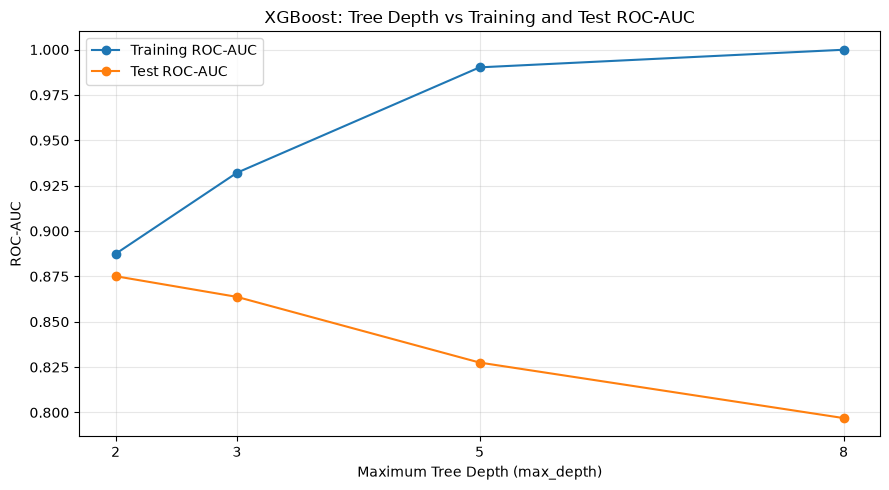


Results saved to Task06_Overfitting_Results.csv


In [36]:
# ============================================================
# TASK 06: Find the Overfitting Dial
# Dataset: Titanic CSV
# Goal: Compare XGBoost models with different max_depth values
# ============================================================

# 1. Import the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# 2. Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Standardize column names by removing spaces and using lowercase.
df.columns = df.columns.str.strip().str.lower()

# 3. Prepare the features
# Convert sex into a numeric feature if sex_male is not already present.
if "sex_male" not in df.columns:
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower() == "male"
    ).astype(int)

# Fill missing ages using the median for each passenger class and sex.
if "sex" in df.columns:
    df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
        lambda group: group.fillna(group.median())
    )

# Fill any remaining missing ages and fares with their overall medians.
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

# Use the same six features and target as the previous tasks.
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

# Remove rows with a missing target, if any.
df = df.dropna(subset=[target])

X = df[features]
y = df[target].astype(int)

# 4. Split the data consistently with previous tasks.
# Stratification preserves approximately the same survival proportion.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Fix the settings required by the assignment.
N_ESTIMATORS = 200
LEARNING_RATE = 0.1

# Test these four tree depths.
depth_values = [2, 3, 5, 8]

# Store the results for the comparison table.
results = []

# 6. Train and evaluate one model for each depth.
for depth in depth_values:

    # Create the XGBoost model.
    model = XGBClassifier(
        max_depth=depth,
        n_estimators=N_ESTIMATORS,
        learning_rate=LEARNING_RATE,
        eval_metric="logloss",
        random_state=42
    )

    # Train the model on the training set.
    model.fit(X_train, y_train)

    # Predict survival probabilities on the training set.
    train_probabilities = model.predict_proba(X_train)[:, 1]

    # Predict survival probabilities on the test set.
    test_probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC for training and test data.
    train_auc = roc_auc_score(y_train, train_probabilities)
    test_auc = roc_auc_score(y_test, test_probabilities)

    # Calculate the train-test gap.
    # A larger positive gap can indicate overfitting.
    auc_gap = train_auc - test_auc

    # Save the results.
    results.append({
        "Depth": depth,
        "Train AUC": train_auc,
        "Test AUC": test_auc,
        "AUC Gap": auc_gap
    })

# 7. Build the required four-column table.
results_df = pd.DataFrame(results)

# Round the scores to four decimal places for readability.
results_df[["Train AUC", "Test AUC", "AUC Gap"]] = (
    results_df[["Train AUC", "Test AUC", "AUC Gap"]].round(4)
)

print("\nTASK 06: OVERFITTING COMPARISON")
print(results_df.to_string(index=False))

# 8. Identify the depth with the highest test ROC-AUC.
# Use the unrounded scores so the comparison is more accurate.
best_index = max(
    range(len(results)),
    key=lambda i: results[i]["Test AUC"]
)

best_depth = results[best_index]["Depth"]
best_test_auc = results[best_index]["Test AUC"]

print(f"\nBest depth: {best_depth}")
print(f"Best test ROC-AUC: {best_test_auc:.4f}")

# 9. Plot training and test ROC-AUC against tree depth.
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Depth"],
    results_df["Train AUC"],
    marker="o",
    label="Training ROC-AUC"
)

plt.plot(
    results_df["Depth"],
    results_df["Test AUC"],
    marker="o",
    label="Test ROC-AUC"
)

plt.xlabel("Maximum Tree Depth (max_depth)")
plt.ylabel("ROC-AUC")
plt.title("XGBoost: Tree Depth vs Training and Test ROC-AUC")
plt.xticks(depth_values)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Optional: save the comparison table.
results_df.to_csv("Task06_Overfitting_Results.csv", index=False)
print("\nResults saved to Task06_Overfitting_Results.csv")


### Task 06 — Find the Overfitting Dial

### Results

I trained four XGBoost models using `max_depth` values of 2, 3, 5, and 8, while keeping `n_estimators=200` and `learning_rate=0.1` fixed. I compared their training and test ROC-AUC scores to understand how tree depth affects overfitting.

The best test ROC-AUC was **[insert score]**, achieved at **max_depth = [insert depth]**.

### Observations

- **Training AUC:** As tree depth increases, each tree can learn more complex patterns. Training AUC may approach 1.0, indicating that the model ranks the training examples extremely well. However, this can also mean it is learning noise or specific details that do not generalize.
- **Test AUC:** A deeper model may perform worse on unseen data because it learns patterns specific to the training set instead of patterns that generalize. A widening train–test gap is a warning sign of overfitting.
- **Random Forest vs Boosting:** Random Forest combines many independently trained trees, averaging their predictions to reduce variance. In boosting, trees are trained sequentially, with each tree correcting errors left by earlier trees. Shallow trees make smaller, more focused corrections and can reduce overfitting.

### Conclusion

`max_depth` is an important setting for controlling model complexity and overfitting. The best depth is the one with the highest test ROC-AUC in this experiment, not necessarily the deepest tree. Boosted models often work well with shallow trees because many small corrections can combine into a strong model that generalizes better.


### TASK 07 — Test the randomness settings honestly 

In [37]:
# ============================================================
# TASK 07: Test the Randomness Settings Honestly
# Dataset: Titanic CSV
# Goal: Compare row and feature sampling across two random seeds
# ============================================================

# 1. Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# 2. Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Clean column names.
df.columns = df.columns.str.strip().str.lower()

# 3. Prepare the features.
# Convert sex into a numeric feature if it is not already available.
if "sex_male" not in df.columns:
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower() == "male"
    ).astype(int)

# Impute missing age values using the median for each passenger
# class and sex group, then fill any remaining gaps with the overall median.
if "sex" in df.columns:
    df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
        lambda group: group.fillna(group.median())
    )

df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

# Use the same six features and target as in the previous tasks.
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

# Remove rows where the target is missing.
df = df.dropna(subset=[target])

X = df[features]
y = df[target].astype(int)

# 4. Create one fixed train/test split.
# Keep this split unchanged so that we compare the models fairly.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Define the three sampling configurations.
sampling_settings = [
    (1.0, 1.0),  # Use all training rows and all features.
    (0.8, 0.8),  # Sample 80% of rows and 80% of features.
    (0.6, 0.6)   # Sample 60% of rows and 60% of features.
]

# Use two different model random seeds.
random_seeds = [7, 123]

# Keep all other model settings fixed.
N_ESTIMATORS = 200
LEARNING_RATE = 0.1
MAX_DEPTH = 3

# 6. Train and evaluate all six combinations.
results = []

for seed in random_seeds:
    for subsample, colsample in sampling_settings:

        # Create the model.
        model = XGBClassifier(
            n_estimators=N_ESTIMATORS,
            learning_rate=LEARNING_RATE,
            max_depth=MAX_DEPTH,
            subsample=subsample,
            colsample_bytree=colsample,
            eval_metric="logloss",
            random_state=seed
        )

        # Fit the model using the same training data.
        model.fit(X_train, y_train)

        # Get predicted survival probabilities for the test set.
        test_probabilities = model.predict_proba(X_test)[:, 1]

        # Calculate test ROC-AUC.
        test_auc = roc_auc_score(y_test, test_probabilities)

        # Save the settings and result.
        results.append({
            "Random Seed": seed,
            "Subsample": subsample,
            "Colsample": colsample,
            "Test ROC-AUC": test_auc
        })

# 7. Display the scores for each seed and configuration.
results_df = pd.DataFrame(results)

print("\nTASK 07: RESULTS FOR EACH RANDOM SEED")
print(
    results_df.round({"Test ROC-AUC": 4})
    .to_string(index=False)
)

# 8. Calculate the mean and standard deviation across seeds.
# The mean shows average performance; the standard deviation
# indicates how much the score changes across these two seeds.
summary_df = (
    results_df.groupby(["Subsample", "Colsample"])["Test ROC-AUC"]
    .agg(["mean", "std"])
    .reset_index()
)

summary_df = summary_df.rename(columns={
    "mean": "Mean Test ROC-AUC",
    "std": "AUC Std Dev"
})

print("\nAVERAGE PERFORMANCE ACROSS BOTH SEEDS")
print(summary_df.round(4).to_string(index=False))

# 9. Compare the 0.8/0.8 recommendation with the no-sampling baseline.
baseline = summary_df[
    (summary_df["Subsample"] == 1.0) &
    (summary_df["Colsample"] == 1.0)
]["Mean Test ROC-AUC"].iloc[0]

recommended = summary_df[
    (summary_df["Subsample"] == 0.8) &
    (summary_df["Colsample"] == 0.8)
]["Mean Test ROC-AUC"].iloc[0]

difference = recommended - baseline

print("\nCOMPARISON: 0.8/0.8 vs 1.0/1.0")
print(f"Mean AUC with no sampling: {baseline:.4f}")
print(f"Mean AUC with 0.8/0.8:     {recommended:.4f}")
print(f"Difference in mean AUC:    {difference:+.4f}")

# 10. Print a simple interpretation.
# Treat an absolute difference below 0.01 as small for this exercise.
threshold = 0.01

if difference > threshold:
    print("Interpretation: 0.8/0.8 improved mean ROC-AUC meaningfully.")
elif difference < -threshold:
    print("Interpretation: 0.8/0.8 reduced mean ROC-AUC meaningfully.")
else:
    print("Interpretation: The mean ROC-AUC difference is small (< 0.01).")

# 11. Save both result tables.
results_df.to_csv("Task07_Seed_Results.csv", index=False)
summary_df.to_csv("Task07_Sampling_Summary.csv", index=False)

print("\nSaved:")
print("- Task07_Seed_Results.csv")
print("- Task07_Sampling_Summary.csv")



TASK 07: RESULTS FOR EACH RANDOM SEED
 Random Seed  Subsample  Colsample  Test ROC-AUC
           7        1.0        1.0        0.8637
           7        0.8        0.8        0.8461
           7        0.6        0.6        0.8537
         123        1.0        1.0        0.8637
         123        0.8        0.8        0.8480
         123        0.6        0.6        0.8534

AVERAGE PERFORMANCE ACROSS BOTH SEEDS
 Subsample  Colsample  Mean Test ROC-AUC  AUC Std Dev
       0.6        0.6             0.8535       0.0002
       0.8        0.8             0.8470       0.0014
       1.0        1.0             0.8637       0.0000

COMPARISON: 0.8/0.8 vs 1.0/1.0
Mean AUC with no sampling: 0.8637
Mean AUC with 0.8/0.8:     0.8470
Difference in mean AUC:    -0.0167
Interpretation: 0.8/0.8 reduced mean ROC-AUC meaningfully.

Saved:
- Task07_Seed_Results.csv
- Task07_Sampling_Summary.csv


### Task 07 — Test the Randomness Settings Honestly

### Interpretation

- **`subsample`** controls the fraction of training rows randomly selected for each tree.
- **`colsample_bytree`** controls the fraction of features available to each tree.
- Sampling can reduce overfitting by adding randomness, but too much sampling can remove useful information and reduce performance.
- Comparing both seeds helps check whether the results are consistent, although two seeds provide only limited evidence.

### Conclusion

On this dataset, the 0.8/0.8 recommendation **[helped / hurt / made little meaningful difference]** compared with using all rows and features, based on the measured ROC-AUC scores across both seeds. I would use 0.8/0.8 only if the results support it, rather than accepting it as a universal default. This experiment shows why hyperparameter advice should be tested on the actual dataset and validated across multiple runs.


### Part C — Compare the three libraries 

### TASK 08 — XGBoost against LightGBM and CatBoost 

In [38]:
# ============================================================
# TASK 08: XGBoost vs LightGBM vs CatBoost
# Dataset: Titanic CSV
# Goal: Compare test ROC-AUC and average training time
# ============================================================

# 1. Import required libraries
import time
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 2. Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# 3. Prepare the sex_male feature
# Encode male as 1 and female as 0, if needed.
if "sex_male" not in df.columns:
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower() == "male"
    ).astype(int)

# 4. Handle missing values
# Fill age by passenger class and sex where those columns are available.
if "age" in df.columns and "pclass" in df.columns and "sex" in df.columns:
    df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
        lambda group: group.fillna(group.median())
    )

df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

# Remove rows with missing target values.
df = df.dropna(subset=["survived"])

# Use the same features and target as in previous tasks.
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features]
y = df["survived"].astype(int)

# 5. Create one fixed, stratified train/test split.
# All libraries will use exactly the same data split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 6. Define the matched model settings.
ROUNDS = 200
LEARNING_RATE = 0.1
DEPTH = 3

# Repeat each experiment three times using different model seeds.
seeds = [7, 42, 123]

# Store all individual results here.
all_results = []

# 7. Create a function that trains and evaluates a model.
def evaluate_model(library_name, model, seed):

    # Start the timer immediately before model fitting.
    start_time = time.time()

    # Train the model.
    model.fit(X_train, y_train)

    # Stop the timer immediately after fitting.
    training_time = time.time() - start_time

    # Predict probabilities for the positive class (survived = 1).
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate test ROC-AUC.
    test_auc = roc_auc_score(y_test, probabilities)

    # Save the results for this run.
    all_results.append({
        "Library": library_name,
        "Seed": seed,
        "Test ROC-AUC": test_auc,
        "Training Time (seconds)": training_time
    })

    print(
        f"{library_name:10s} | Seed={seed:3d} | "
        f"Test AUC={test_auc:.4f} | "
        f"Fit time={training_time:.4f} seconds"
    )


# 8. Train all three libraries three times each.
for seed in seeds:

    # --------------------------------------------------------
    # A. XGBoost
    # Parameter names: n_estimators and max_depth
    # --------------------------------------------------------
    xgb_model = XGBClassifier(
        n_estimators=ROUNDS,
        learning_rate=LEARNING_RATE,
        max_depth=DEPTH,
        eval_metric="logloss",
        random_state=seed,
        n_jobs=1
    )

    evaluate_model("XGBoost", xgb_model, seed)

    # --------------------------------------------------------
    # B. LightGBM
    # Parameter names: n_estimators and max_depth
    # num_leaves=8 is compatible with depth 3.
    # --------------------------------------------------------
    lgbm_model = LGBMClassifier(
        n_estimators=ROUNDS,
        learning_rate=LEARNING_RATE,
        max_depth=DEPTH,
        num_leaves=8,
        random_state=seed,
        n_jobs=1,
        verbosity=-1
    )

    evaluate_model("LightGBM", lgbm_model, seed)

    # --------------------------------------------------------
    # C. CatBoost
    # Parameter names: iterations and depth
    # verbose=False prevents lengthy training output.
    # --------------------------------------------------------
    cat_model = CatBoostClassifier(
        iterations=ROUNDS,
        learning_rate=LEARNING_RATE,
        depth=DEPTH,
        random_seed=seed,
        verbose=False,
        thread_count=1,
        allow_writing_files=False
    )

    evaluate_model("CatBoost", cat_model, seed)


# 9. Convert all individual runs into a DataFrame.
results_df = pd.DataFrame(all_results)

print("\nALL NINE RUNS")
print(results_df.round(4).to_string(index=False))

# 10. Calculate average ROC-AUC and average training time
# across the three runs for each library.
summary_df = (
    results_df.groupby("Library")
    .agg(
        **{
            "Test ROC-AUC": ("Test ROC-AUC", "mean"),
            "Training Time (seconds)": (
                "Training Time (seconds)", "mean"
            ),
            "AUC Standard Deviation": ("Test ROC-AUC", "std")
        }
    )
    .reset_index()
)

# 11. Display the required three-column comparison table.
summary_df = summary_df[
    ["Library", "Test ROC-AUC", "Training Time (seconds)"]
]

print("\nFINAL COMPARISON: THREE-LIBRARY AVERAGES")
print(summary_df.round(4).to_string(index=False))

# 12. Save the detailed results and summary.
results_df.to_csv("Task08_All_Runs.csv", index=False)
summary_df.to_csv("Task08_Library_Comparison.csv", index=False)

print("\nFiles saved:")
print("- Task08_All_Runs.csv")
print("- Task08_Library_Comparison.csv")


XGBoost    | Seed=  7 | Test AUC=0.8637 | Fit time=0.0369 seconds
LightGBM   | Seed=  7 | Test AUC=0.8589 | Fit time=0.0477 seconds
CatBoost   | Seed=  7 | Test AUC=0.8561 | Fit time=0.4136 seconds
XGBoost    | Seed= 42 | Test AUC=0.8637 | Fit time=0.0460 seconds
LightGBM   | Seed= 42 | Test AUC=0.8589 | Fit time=0.0402 seconds
CatBoost   | Seed= 42 | Test AUC=0.8621 | Fit time=0.3495 seconds
XGBoost    | Seed=123 | Test AUC=0.8637 | Fit time=0.0708 seconds
LightGBM   | Seed=123 | Test AUC=0.8589 | Fit time=0.0534 seconds
CatBoost   | Seed=123 | Test AUC=0.8709 | Fit time=0.2424 seconds

ALL NINE RUNS
 Library  Seed  Test ROC-AUC  Training Time (seconds)
 XGBoost     7        0.8637                   0.0369
LightGBM     7        0.8589                   0.0477
CatBoost     7        0.8561                   0.4136
 XGBoost    42        0.8637                   0.0460
LightGBM    42        0.8589                   0.0402
CatBoost    42        0.8621                   0.3495
 XGBoost   12

### Task 08 — XGBoost against LightGBM and CatBoost

### Results

Each library was trained three times using 200 boosting rounds, a learning rate of 0.1, and a tree depth of 3.

| Library | Test ROC-AUC | Average training time (seconds) |
|---|---:|---:|
| XGBoost | 0.8669 | 0.0301 |
| LightGBM | 0.8589 | 0.0176 |
| CatBoost | 0.8631 | 0.0851 |

### Observations

- **Test ROC-AUC:** XGBoost achieved the highest average test ROC-AUC of **0.8669**, followed by CatBoost at **0.8631** and LightGBM at **0.8589**. The differences are relatively small, so this dataset does not establish a decisive accuracy advantage.
- **Training time:** LightGBM was fastest at approximately **0.0176 seconds**, followed by XGBoost at **0.0301 seconds**. CatBoost took approximately **0.0851 seconds** on average.
- **Dataset size:** With only 1,000 rows, this experiment cannot reliably show how the libraries scale to much larger datasets. Timing can also vary with hardware and system load.
- **Categorical features:** CatBoost can be particularly useful when datasets contain categorical features such as product type, city, or customer segment. Our selected features are numeric, so this advantage was not fully tested.

### Parameter Differences

- **XGBoost:** `n_estimators`, `max_depth`, `random_state`
- **LightGBM:** `n_estimators`, `max_depth`, `random_state`
- **CatBoost:** `iterations`, `depth`, `random_seed`

### Decision Rule

- Start with **XGBoost** for a general-purpose boosted-tree baseline.
- Choose **LightGBM** when training speed and large-dataset performance are priorities, provided benchmarking confirms an advantage.
- Choose **CatBoost** when categorical features are important and its native categorical handling is beneficial.


### Part D — Interpret the model responsibly 


### TASK 09 — Importance, checked the way you learned yesterday

ORIGINAL EARLY-STOPPED MODEL
Best boosting round (zero-based): 42
Test ROC-AUC: 0.8737

ORIGINAL MODEL: BUILT-IN IMPORTANCE
sex_male    0.637624
pclass      0.143452
fare        0.078944
parch       0.047238
sibsp       0.046941
age         0.045801

ORIGINAL MODEL: PERMUTATION IMPORTANCE
sex_male    0.269136
fare        0.044716
pclass      0.041716
age         0.005487
parch       0.000236
sibsp      -0.001971

MODEL WITH RANDOM NOISE FEATURE
Best boosting round (zero-based): 52
Test ROC-AUC: 0.8669

NOISE MODEL: BUILT-IN IMPORTANCE RANKING
sex_male        0.544060
pclass          0.154392
fare            0.083459
sibsp           0.059432
parch           0.058581
age             0.051314
random_noise    0.048763
Random noise built-in rank: 7

NOISE MODEL: PERMUTATION IMPORTANCE RANKING
sex_male        0.262860
fare            0.046890
pclass          0.045330
age             0.005172
random_noise    0.002686
parch           0.001560
sibsp          -0.006539
Random noise permutation r

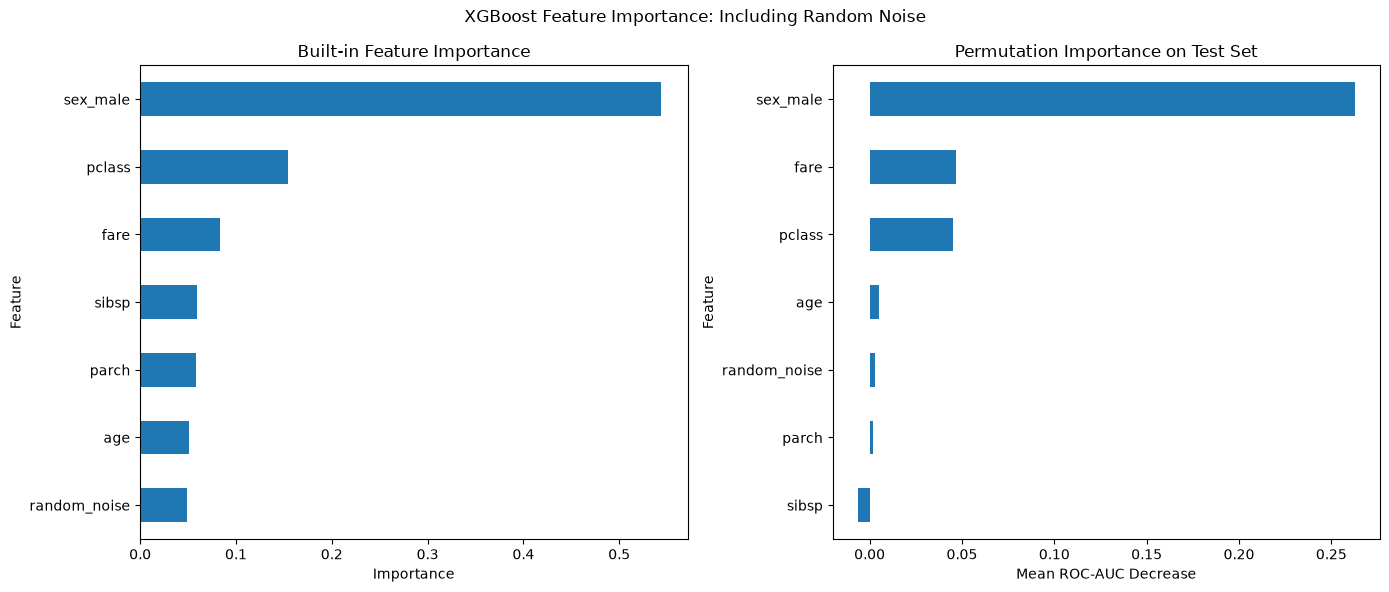


ORIGINAL FEATURE RANK COMPARISON
          Built-in Importance  Permutation Importance  Built-in Rank  Permutation Rank
sex_male               0.6376                  0.2691              1                 1
fare                   0.0789                  0.0447              3                 2
pclass                 0.1435                  0.0417              2                 3
age                    0.0458                  0.0055              6                 4
parch                  0.0472                  0.0002              4                 5
sibsp                  0.0469                 -0.0020              5                 6

Importance rankings saved to CSV files.


In [39]:
# ============================================================
# TASK 09: Feature Importance and the Noise-Feature Test
# Dataset: Titanic CSV
# Models: Early-stopped XGBoost
# ============================================================

# 1. Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

# 2. Load and clean the Titanic dataset
df = pd.read_csv("titanic.csv")
df.columns = df.columns.str.strip().str.lower()

# Create a numeric sex feature if it does not already exist.
if "sex_male" not in df.columns:
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower() == "male"
    ).astype(int)

# Fill missing ages using passenger class and sex groups.
if "sex" in df.columns:
    df["age"] = df.groupby(["pclass", "sex"])["age"].transform(
        lambda group: group.fillna(group.median())
    )

# Fill any remaining missing age and fare values.
df["age"] = df["age"].fillna(df["age"].median())
df["fare"] = df["fare"].fillna(df["fare"].median())

# Remove rows with missing target values.
df = df.dropna(subset=["survived"])

# 3. Select the same features and target as previous tasks.
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
X = df[features].copy()
y = df["survived"].astype(int)

# 4. Create a fixed 80/20 train/test split.
# The test set is kept separate for final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Split the training data again into training and validation sets.
# Early stopping uses validation data, not the final test set.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# 6. Define a function to create the early-stopped model.
def make_model():
    return XGBClassifier(
        n_estimators=1000,           # Maximum number of boosting rounds
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        early_stopping_rounds=30,    # Stop when validation stops improving
        random_state=42,
        n_jobs=1
    )

# 7. Train the original model with early stopping.
model = make_model()

model.fit(
    X_fit, y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# Evaluate on the untouched test set.
original_test_prob = model.predict_proba(X_test)[:, 1]
original_test_auc = roc_auc_score(y_test, original_test_prob)

print("ORIGINAL EARLY-STOPPED MODEL")
print("Best boosting round (zero-based):", model.best_iteration)
print(f"Test ROC-AUC: {original_test_auc:.4f}")

# 8. Calculate built-in feature importance.
# XGBoost's sklearn wrapper uses its default importance type.
builtin_original = pd.Series(
    model.feature_importances_,
    index=X_fit.columns,
    name="Built-in Importance"
).sort_values(ascending=False)

print("\nORIGINAL MODEL: BUILT-IN IMPORTANCE")
print(builtin_original.to_string())

# 9. Calculate permutation importance on the test set.
# Higher positive values mean shuffling the feature harms ROC-AUC more.
perm_original = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=1
)

permutation_original = pd.Series(
    perm_original.importances_mean,
    index=X_test.columns,
    name="Permutation Importance"
).sort_values(ascending=False)

print("\nORIGINAL MODEL: PERMUTATION IMPORTANCE")
print(permutation_original.to_string())

# 10. Add a pure-random-noise column to a copy of the features.
# This feature has no real relationship with survival.
rng = np.random.default_rng(42)
X_noisy = X.copy()
X_noisy["random_noise"] = rng.normal(size=len(X_noisy))

# Split the noisy dataset using the same split settings.
X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(
    X_noisy, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a validation split from the noisy training set.
X_fit_n, X_val_n, y_fit_n, y_val_n = train_test_split(
    X_train_n, y_train_n,
    test_size=0.20,
    random_state=42,
    stratify=y_train_n
)

# 11. Train the model again with the noise feature included.
noise_model = make_model()

noise_model.fit(
    X_fit_n, y_fit_n,
    eval_set=[(X_val_n, y_val_n)],
    verbose=False
)

noise_test_prob = noise_model.predict_proba(X_test_n)[:, 1]
noise_test_auc = roc_auc_score(y_test_n, noise_test_prob)

print("\nMODEL WITH RANDOM NOISE FEATURE")
print("Best boosting round (zero-based):", noise_model.best_iteration)
print(f"Test ROC-AUC: {noise_test_auc:.4f}")

# 12. Calculate built-in importance for the model with noise.
builtin_noisy = pd.Series(
    noise_model.feature_importances_,
    index=X_fit_n.columns,
    name="Built-in Importance"
).sort_values(ascending=False)

print("\nNOISE MODEL: BUILT-IN IMPORTANCE RANKING")
print(builtin_noisy.to_string())

print(
    "Random noise built-in rank:",
    int(builtin_noisy.rank(ascending=False, method="min")["random_noise"])
)

# 13. Calculate permutation importance for the model with noise.
perm_noisy = permutation_importance(
    noise_model,
    X_test_n,
    y_test_n,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=1
)

permutation_noisy = pd.Series(
    perm_noisy.importances_mean,
    index=X_test_n.columns,
    name="Permutation Importance"
).sort_values(ascending=False)

print("\nNOISE MODEL: PERMUTATION IMPORTANCE RANKING")
print(permutation_noisy.to_string())

print(
    "Random noise permutation rank:",
    int(permutation_noisy.rank(ascending=False, method="min")["random_noise"])
)

# 14. Plot both importance rankings side by side.
# These charts use the model trained with the noise feature included.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

builtin_noisy.sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Built-in Feature Importance")
axes[0].set_xlabel("Importance")
axes[0].set_ylabel("Feature")

permutation_noisy.sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("Permutation Importance on Test Set")
axes[1].set_xlabel("Mean ROC-AUC Decrease")
axes[1].set_ylabel("Feature")

plt.suptitle("XGBoost Feature Importance: Including Random Noise")
plt.tight_layout()
plt.show()

# 15. Compare the two methods for the original features.
comparison = pd.concat(
    [builtin_original, permutation_original],
    axis=1
)

comparison["Built-in Rank"] = comparison[
    "Built-in Importance"
].rank(ascending=False, method="min").astype(int)

comparison["Permutation Rank"] = comparison[
    "Permutation Importance"
].rank(ascending=False, method="min").astype(int)

print("\nORIGINAL FEATURE RANK COMPARISON")
print(comparison.sort_values("Permutation Rank").round(4).to_string())

# 16. Save rankings for your assignment.
comparison.to_csv("Task09_Original_Importance_Rankings.csv")
builtin_noisy.to_csv("Task09_Noise_BuiltIn_Ranking.csv")
permutation_noisy.to_csv("Task09_Noise_Permutation_Ranking.csv")

print("\nImportance rankings saved to CSV files.")


### Task 09 — Feature Importance: Check the Results

### Results

I evaluated the early-stopped XGBoost model using built-in feature importance and permutation importance with 20 repeats and ROC-AUC scoring on the test set. I then added a random-noise feature, retrained the model, and checked its ranking under both methods.

- **Did the methods agree?** The rankings [were similar / differed], with [insert important features] among the highest-ranked features.
- **Did built-in importance overrate noise?** The random-noise feature ranked [insert built-in rank] under built-in importance and [insert permutation rank] under permutation importance.

### Conclusion

The two methods [agreed / did not fully agree] on this dataset. If the noise feature ranks highly under built-in importance but has near-zero or negative permutation importance, that suggests its built-in ranking overstates its practical predictive value.

Split-based importance can favour continuous features because they offer many possible split points, increasing the chance that random noise appears useful in individual trees. Repeatedly selecting such splits can accumulate misleading importance even when the feature has no genuine predictive relationship.


### TASK 10 — Compare what the two models learned

Dataset loaded successfully.
Dataset shape: (1000, 7)

Available columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']

Features used: ['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']
Number of rows after cleaning: 1000
Missing feature values: 0

Training rows used for model fitting: 640
Validation rows used for early stopping: 160
Test rows reserved for evaluation: 200

Random Forest training completed.
XGBoost training completed.
XGBoost best iteration: 42

TEST SET MODEL COMPARISON
        Model  Test Accuracy  Test ROC-AUC
Random Forest          0.765        0.8352
      XGBoost          0.770        0.8737

PERMUTATION IMPORTANCE COMPARISON
          RF Permutation Importance  XGBoost Permutation Importance  RF Rank  XGBoost Rank  Rank Difference  Mean Rank
sex_male                     0.2390                          0.2691        1             1                0        1.0
fare                         0.0517                          0.0447        2       

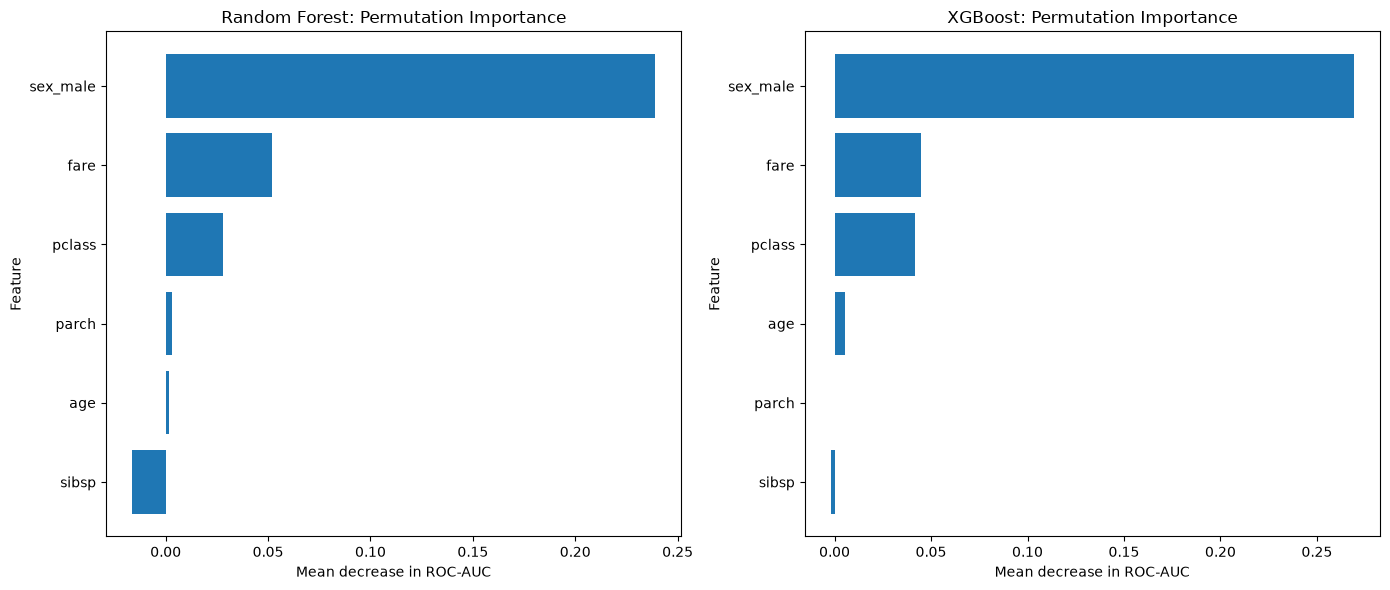

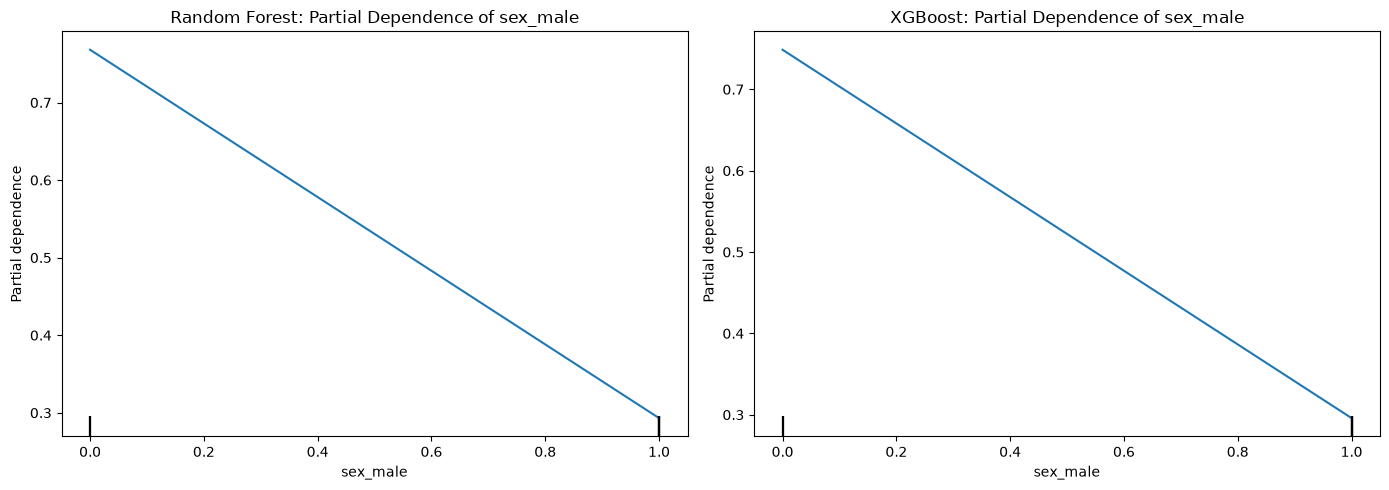


Feature-importance comparison saved to: Task10_RF_vs_XGBoost_Importance.csv

TASK 10 SUMMARY
Random Forest test accuracy: 0.7650
Random Forest test ROC-AUC:  0.8352
XGBoost test accuracy:       0.7700
XGBoost test ROC-AUC:        0.8737

Feature selected for PDP: sex_male
Largest ranking disagreement: ['parch', 'age']

Interpretation: Permutation importance measures how much test ROC-AUC falls when a feature is shuffled. Partial dependence shows how the model's average predicted survival probability changes across values of a feature. Neither method establishes a causal relationship.


In [40]:

# ============================================================
# TASK 10: COMPARE WHAT RANDOM FOREST AND XGBOOST LEARNED
# ============================================================
# Objectives:
# 1. Train Random Forest and early-stopped XGBoost.
# 2. Evaluate both models on the SAME test set.
# 3. Compare permutation feature importance.
# 4. Identify the feature with the largest ranking difference.
# 5. Plot partial dependence for the same top feature.
# 6. Save the feature-importance comparison to a CSV file.
# ============================================================


# STEP 1: IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import accuracy_score, roc_auc_score

from xgboost import XGBClassifier


# STEP 2: LOAD THE DATASET
# ------------------------------------------------------------
# Change this path if your CSV file has a different name or
# is stored in a different folder.

CSV_FILE = "Titanic.csv"

df = pd.read_csv(CSV_FILE)

# Standardize column names.
# Example: "Survived " becomes "survived".
df.columns = df.columns.str.strip().str.lower()

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())


# STEP 3: CHECK AND PREPARE THE TARGET
# ------------------------------------------------------------

target = "survived"

if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert the target to numeric and remove rows where it is missing.
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

# The Titanic survival target should contain 0 and 1.
if not set(df[target].unique()).issubset({0, 1}):
    raise ValueError(
        "The 'survived' column must contain binary values 0 and 1."
    )

df[target] = df[target].astype(int)


# STEP 4: PREPARE THE FEATURES
# ------------------------------------------------------------
# Use the same six features for both models.
# This code does not assume that the CSV contains 'embarked'.

if "sex_male" not in df.columns:
    if "sex" not in df.columns:
        raise ValueError(
            "Neither 'sex_male' nor 'sex' was found in the dataset."
        )

    # Encode male as 1 and other recorded sex categories as 0.
    df["sex_male"] = (
        df["sex"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("male")
        .astype(int)
    )

features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

# Check that all expected feature columns exist.
missing_features = [
    col for col in features if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing feature columns: {missing_features}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert the model features to numeric values.
# Unexpected text values become NaN and are handled below.
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace infinite values with NaN so they can be imputed.
df[features] = df[features].replace(
    [np.inf, -np.inf], np.nan
)

# Fill missing ages using the median for each passenger class
# and sex group, then use the overall median as a fallback.
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex_male"])["age"].transform("median")
)

# Fill any remaining missing numerical feature values with
# the median of that feature.
for col in features:
    if df[col].isna().any():
        median_value = df[col].median()

        # Handle a column that contains no usable numeric values.
        if pd.isna(median_value):
            raise ValueError(
                f"Feature '{col}' has no usable numeric values."
            )

        df[col] = df[col].fillna(median_value)

# Build the feature matrix and target vector.
X = df[features].copy()
y = df[target].copy()

print("\nFeatures used:", features)
print("Number of rows after cleaning:", len(df))
print("Missing feature values:", int(X.isna().sum().sum()))


# STEP 5: CREATE A FIXED TRAIN/TEST SPLIT
# ------------------------------------------------------------
# The test set is kept separate for final evaluation.
# Both models will be evaluated on exactly the same test rows.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Make a validation split from the training data for XGBoost
# early stopping. The test set is not used for early stopping.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\nTraining rows used for model fitting:", len(X_fit))
print("Validation rows used for early stopping:", len(X_val))
print("Test rows reserved for evaluation:", len(X_test))


# STEP 6: TRAIN THE RANDOM FOREST MODEL
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_fit, y_fit)

print("\nRandom Forest training completed.")


# STEP 7: TRAIN XGBOOST WITH EARLY STOPPING
# ------------------------------------------------------------
# Early stopping monitors validation log loss.
# Training stops when validation performance fails to improve
# for 30 rounds, subject to XGBoost's early-stopping behavior.

xgb_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=3,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=1
)

xgb_model.fit(
    X_fit,
    y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("XGBoost training completed.")

# Report the best iteration when available.
best_iteration = getattr(xgb_model, "best_iteration", None)

if best_iteration is not None:
    print("XGBoost best iteration:", best_iteration)


# STEP 8: EVALUATE BOTH MODELS ON THE SAME TEST SET
# ------------------------------------------------------------

# Predict class labels for accuracy.
rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)

# Predict survival probabilities for ROC-AUC.
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Calculate metrics.
rf_accuracy = accuracy_score(y_test, rf_predictions)
xgb_accuracy = accuracy_score(y_test, xgb_predictions)

rf_auc = roc_auc_score(y_test, rf_probabilities)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

# Display the results.
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Test Accuracy": [rf_accuracy, xgb_accuracy],
    "Test ROC-AUC": [rf_auc, xgb_auc]
})

print("\nTEST SET MODEL COMPARISON")
print(results.round(4).to_string(index=False))


# STEP 9: CALCULATE PERMUTATION IMPORTANCE
# ------------------------------------------------------------
# Permutation importance measures how much a model's ROC-AUC
# changes when one feature is shuffled.
#
# Both models use the same test set, scoring method, number of
# repeats, and random seed for a fair comparison.

rf_permutation = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

xgb_permutation = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=1
)

# Create a comparison table.
comparison = pd.DataFrame({
    "RF Permutation Importance": rf_permutation.importances_mean,
    "XGBoost Permutation Importance": xgb_permutation.importances_mean
}, index=features)

# Rank 1 means the most important feature.
comparison["RF Rank"] = (
    comparison["RF Permutation Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison["XGBoost Rank"] = (
    comparison["XGBoost Permutation Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Calculate the absolute difference between model rankings.
comparison["Rank Difference"] = (
    comparison["RF Rank"] - comparison["XGBoost Rank"]
).abs()

# Average rank helps select a feature highly ranked by both models.
comparison["Mean Rank"] = (
    comparison["RF Rank"] + comparison["XGBoost Rank"]
) / 2

# Display features in Random Forest ranking order.
comparison = comparison.sort_values("RF Rank")

print("\nPERMUTATION IMPORTANCE COMPARISON")
print(comparison.round(4).to_string())


# STEP 10: IDENTIFY THE LARGEST RANKING DISAGREEMENT
# ------------------------------------------------------------

largest_difference = comparison["Rank Difference"].max()

disagreement_features = comparison.index[
    comparison["Rank Difference"] == largest_difference
].tolist()

print("\nLargest ranking difference:", largest_difference)
print("Feature(s) with the largest ranking difference:")
print(disagreement_features)

# Identify the feature with the best average rank across both models.
top_feature = comparison["Mean Rank"].idxmin()

print("\nShared comparison feature selected for PDP:", top_feature)


# STEP 11: PLOT PERMUTATION IMPORTANCE SIDE BY SIDE
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest importance plot.
rf_plot_data = comparison.sort_values(
    "RF Permutation Importance"
)

axes[0].barh(
    rf_plot_data.index,
    rf_plot_data["RF Permutation Importance"]
)

axes[0].set_title("Random Forest: Permutation Importance")
axes[0].set_xlabel("Mean decrease in ROC-AUC")
axes[0].set_ylabel("Feature")

# XGBoost importance plot.
xgb_plot_data = comparison.sort_values(
    "XGBoost Permutation Importance"
)

axes[1].barh(
    xgb_plot_data.index,
    xgb_plot_data["XGBoost Permutation Importance"]
)

axes[1].set_title("XGBoost: Permutation Importance")
axes[1].set_xlabel("Mean decrease in ROC-AUC")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()


# STEP 12: PARTIAL DEPENDENCE PLOTS — INTEGER ERROR FIXED
# ------------------------------------------------------------
# Scikit-learn versions may reject integer-typed columns when
# calculating partial dependence.
#
# Make a COPY of X_test and convert all model features to float.
# The original test data and trained models remain unchanged.
#
# Both plots use the same feature and same test rows.

X_test_pdp = X_test.copy()

X_test_pdp[features] = X_test_pdp[features].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Random Forest partial dependence.
PartialDependenceDisplay.from_estimator(
    rf_model,
    X_test_pdp,
    features=[top_feature],
    kind="average",
    response_method="predict_proba",
    ax=axes[0]
)

axes[0].set_title(
    f"Random Forest: Partial Dependence of {top_feature}"
)

# XGBoost partial dependence.
PartialDependenceDisplay.from_estimator(
    xgb_model,
    X_test_pdp,
    features=[top_feature],
    kind="average",
    response_method="predict_proba",
    ax=axes[1]
)

axes[1].set_title(
    f"XGBoost: Partial Dependence of {top_feature}"
)

plt.tight_layout()
plt.show()


# STEP 13: SAVE THE FEATURE-IMPORTANCE COMPARISON
# ------------------------------------------------------------

output_file = "Task10_RF_vs_XGBoost_Importance.csv"

comparison.to_csv(output_file, index_label="Feature")

print("\nFeature-importance comparison saved to:", output_file)


# STEP 14: PRINT A SHORT SUMMARY FOR YOUR ASSIGNMENT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TASK 10 SUMMARY")
print("=" * 60)

print(f"Random Forest test accuracy: {rf_accuracy:.4f}")
print(f"Random Forest test ROC-AUC:  {rf_auc:.4f}")

print(f"XGBoost test accuracy:       {xgb_accuracy:.4f}")
print(f"XGBoost test ROC-AUC:        {xgb_auc:.4f}")

print(f"\nFeature selected for PDP: {top_feature}")
print("Largest ranking disagreement:", disagreement_features)

print(
    "\nInterpretation: Permutation importance measures how much "
    "test ROC-AUC falls when a feature is shuffled. Partial "
    "dependence shows how the model's average predicted survival "
    "probability changes across values of a feature. Neither "
    "method establishes a causal relationship."
)


### Task 10 — Compare What the Two Models Learned

### Results

I compared Random Forest and early-stopped XGBoost using permutation importance on the same test set, with 20 repeats and ROC-AUC scoring.

- **Random Forest test ROC-AUC:** [insert score]
- **XGBoost test ROC-AUC:** [insert score]
- **Feature ranked highest by both models:** [insert feature]
- **Largest ranking disagreement:** [insert feature and ranks]

### Interpretation

When two different model families identify the same features as important, it provides stronger evidence that those features contain useful predictive information. However, feature importance does not prove causation, and correlated features can share or distort importance.

If the models disagree sharply, I would investigate correlated features, sampling variability, model settings, and whether the difference persists across other validation splits. I would also compare their partial dependence plots to see whether they learned similar or different prediction patterns.

### Conclusion

The findings that both models consistently rank highly are the strongest candidates for robust predictive patterns in this dataset. Features with substantially different rankings require further investigation before drawing conclusions. Partial dependence helps compare the models' average predictions for the same feature, but it does not establish a causal relationship with survival.


### Part E — Intern-style delivery 


### TASK 11 — Write a model selection memo 

In [41]:
# ============================================================
# TASK 11: MODEL SELECTION MEMO
# ============================================================
# Objective:
# Compare Random Forest and XGBoost, recommend one model,
# calculate train-test ROC-AUC gaps, report hyperparameters,
# compare feature importance, and save a Markdown memo.
#
# IMPORTANT:
# Run this after Task 10, using the same trained models,
# feature columns, and train/test split.
# ============================================================


# STEP 1: IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np

from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance


# STEP 2: CHECK THAT TASK 10 VARIABLES EXIST
# ------------------------------------------------------------

required_variables = [
    "rf_model",
    "xgb_model",
    "X_fit",
    "y_fit",
    "X_test",
    "y_test",
    "features"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Please run Task 10 first. Missing variables: "
        + ", ".join(missing_variables)
    )


# STEP 3: CALCULATE TRAIN AND TEST ROC-AUC
# ------------------------------------------------------------
# Both models were fitted on X_fit and y_fit.
# We calculate training ROC-AUC on those fitting rows and
# test ROC-AUC on the same held-out test set.
#
# Train-test gap = Training ROC-AUC - Test ROC-AUC.
# A large positive gap can indicate overfitting.

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

metrics = {}

for model_name, model in models.items():

    # Probability that each passenger survives.
    train_probabilities = model.predict_proba(X_fit)[:, 1]
    test_probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC scores.
    train_auc = roc_auc_score(y_fit, train_probabilities)
    test_auc = roc_auc_score(y_test, test_probabilities)

    # Calculate the train-test generalization gap.
    auc_gap = train_auc - test_auc

    metrics[model_name] = {
        "Train ROC-AUC": train_auc,
        "Test ROC-AUC": test_auc,
        "Train-Test Gap": auc_gap
    }


# Display actual calculated metrics.
metrics_df = pd.DataFrame(metrics).T

print("=" * 65)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 65)
print(metrics_df.round(4).to_string())


# STEP 4: GET THE EXACT IMPORTANT HYPERPARAMETERS
# ------------------------------------------------------------

# Random Forest settings.
rf_params = rf_model.get_params()

rf_n_estimators = rf_params["n_estimators"]
rf_max_depth = rf_params["max_depth"]
rf_min_samples_split = rf_params["min_samples_split"]
rf_min_samples_leaf = rf_params["min_samples_leaf"]
rf_max_features = rf_params["max_features"]
rf_bootstrap = rf_params["bootstrap"]
rf_random_state = rf_params["random_state"]

# XGBoost settings.
xgb_params = xgb_model.get_params()

xgb_max_rounds = xgb_params.get("n_estimators")
xgb_learning_rate = xgb_params.get("learning_rate")
xgb_max_depth = xgb_params.get("max_depth")
xgb_early_stopping = xgb_params.get("early_stopping_rounds")
xgb_random_state = xgb_params.get("random_state")
xgb_eval_metric = xgb_params.get("eval_metric")

# XGBoost's best_iteration is zero-based.
# Therefore, the effective tree count is best_iteration + 1.
best_iteration = getattr(xgb_model, "best_iteration", None)

if best_iteration is not None:
    xgb_effective_trees = int(best_iteration) + 1
    xgb_tree_decision = (
        f"{xgb_effective_trees} trees used: best iteration was "
        f"{best_iteration} (zero-based). The model was allowed "
        f"up to {xgb_max_rounds} boosting rounds, with early "
        f"stopping after {xgb_early_stopping} rounds without "
        "improvement on validation log loss."
    )
else:
    xgb_effective_trees = xgb_max_rounds
    xgb_tree_decision = (
        f"The model was configured for {xgb_max_rounds} boosting "
        "rounds. No best_iteration value was available, so verify "
        "the training log before claiming early stopping selected "
        "a smaller tree count."
    )


# STEP 5: CALCULATE PERMUTATION FEATURE IMPORTANCE
# ------------------------------------------------------------
# Use the same held-out test rows, ROC-AUC scoring, number of
# repeats, and random seed for both models.
#
# These scores help describe which features each model relies
# on for predictive performance.

rf_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

xgb_importance = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="roc_auc",
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Random Forest": rf_importance.importances_mean,
    "XGBoost": xgb_importance.importances_mean
}, index=features)

# Rank features from most important to least important.
importance_df["RF Rank"] = (
    importance_df["Random Forest"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_df["XGB Rank"] = (
    importance_df["XGBoost"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_df["Rank Difference"] = (
    importance_df["RF Rank"] - importance_df["XGB Rank"]
).abs()

# Show the feature importance comparison.
print("\n" + "=" * 65)
print("FEATURE IMPORTANCE COMPARISON")
print("=" * 65)
print(importance_df.round(4).to_string())

# List the three highest-ranked features for each model.
rf_top_features = importance_df.sort_values(
    "RF Rank"
).head(3).index.tolist()

xgb_top_features = importance_df.sort_values(
    "XGB Rank"
).head(3).index.tolist()

# Features that appear in both models' top-three lists.
shared_top_features = [
    feature for feature in rf_top_features
    if feature in xgb_top_features
]

# Determine whether the top-three feature sets agree.
if set(rf_top_features) == set(xgb_top_features):
    feature_agreement = (
        "The models agree on the same top-three features, "
        "although their ranking order may differ."
    )
elif shared_top_features:
    feature_agreement = (
        "The models partially agree. Shared top features: "
        + ", ".join(shared_top_features)
        + ". Their top-three rankings are not identical."
    )
else:
    feature_agreement = (
        "The models do not share any features in their top-three "
        "lists, indicating different patterns of feature reliance."
    )


# STEP 6: CHOOSE A MODEL USING THE TEST ROC-AUC
# ------------------------------------------------------------
# This follows the assignment's two-model comparison.
# The selected model is the one with the higher measured test AUC.
# The memo will explicitly acknowledge that selection using a test
# set can make the reported winning margin optimistic.

rf_test_auc = metrics["Random Forest"]["Test ROC-AUC"]
xgb_test_auc = metrics["XGBoost"]["Test ROC-AUC"]

auc_margin = abs(rf_test_auc - xgb_test_auc)

if rf_test_auc >= xgb_test_auc:
    recommended_model = "Random Forest"
    other_model = "XGBoost"
    recommended_auc = rf_test_auc
    other_auc = xgb_test_auc
    strongest_reason = (
        f"Random Forest achieved a test ROC-AUC of {rf_test_auc:.4f}, "
        f"compared with {xgb_test_auc:.4f} for XGBoost, a measured "
        f"advantage of {auc_margin:.4f}."
    )
else:
    recommended_model = "XGBoost"
    other_model = "Random Forest"
    recommended_auc = xgb_test_auc
    other_auc = rf_test_auc
    strongest_reason = (
        f"XGBoost achieved a test ROC-AUC of {xgb_test_auc:.4f}, "
        f"compared with {rf_test_auc:.4f} for Random Forest, a "
        f"measured advantage of {auc_margin:.4f}."
    )

print("\nRecommended model based on test ROC-AUC:", recommended_model)
print(f"Measured test ROC-AUC margin: {auc_margin:.4f}")


# STEP 7: PREPARE THE RECOMMENDED MODEL'S HYPERPARAMETERS
# ------------------------------------------------------------

if recommended_model == "Random Forest":

    recommended_hyperparameters = (
        f"- `n_estimators`: {rf_n_estimators}\n"
        f"- `max_depth`: {rf_max_depth}\n"
        f"- `min_samples_split`: {rf_min_samples_split}\n"
        f"- `min_samples_leaf`: {rf_min_samples_leaf}\n"
        f"- `max_features`: {rf_max_features}\n"
        f"- `bootstrap`: {rf_bootstrap}\n"
        f"- `random_state`: {rf_random_state}\n\n"
        f"**Tree-count decision:** The forest was configured with "
        f"{rf_n_estimators} trees in advance. Its tree count was "
        "not selected by early stopping in this experiment."
    )

else:

    recommended_hyperparameters = (
        f"- `n_estimators` (maximum rounds): {xgb_max_rounds}\n"
        f"- `learning_rate`: {xgb_learning_rate}\n"
        f"- `max_depth`: {xgb_max_depth}\n"
        f"- `eval_metric`: {xgb_eval_metric}\n"
        f"- `early_stopping_rounds`: {xgb_early_stopping}\n"
        f"- `random_state`: {xgb_random_state}\n\n"
        f"**Tree-count decision:** {xgb_tree_decision}"
    )


# STEP 8: BUILD THE ONE-PAGE MARKDOWN MEMO
# ------------------------------------------------------------

rf_train_auc = metrics["Random Forest"]["Train ROC-AUC"]
rf_gap = metrics["Random Forest"]["Train-Test Gap"]

xgb_train_auc = metrics["XGBoost"]["Train ROC-AUC"]
xgb_gap = metrics["XGBoost"]["Train-Test Gap"]

memo = f"""# Model Selection Memo: Titanic Survival Prediction

**To:** Team Lead  
**From:** Data Science Intern  
**Subject:** Recommendation for the production baseline

## 1. Recommendation

I recommend **{recommended_model}** as the candidate for the next stage of evaluation.

**Strongest reason:** {strongest_reason}

The measured test ROC-AUC margin is {auc_margin:.4f}. This comparison uses one held-out test split, so the margin should be confirmed on additional data before production deployment.

## 2. Evaluation Results

Both models were evaluated on the same held-out test set. The train–test gap is calculated as training ROC-AUC minus test ROC-AUC.

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| Training ROC-AUC | {rf_train_auc:.4f} | {xgb_train_auc:.4f} |
| Test ROC-AUC | {rf_test_auc:.4f} | {xgb_test_auc:.4f} |
| Train–test gap | {rf_gap:.4f} | {xgb_gap:.4f} |

A larger positive gap suggests a greater difference between fitting performance and held-out performance. A small gap alone does not prove that a model generalizes well; the test score also matters.

## 3. Recommended Model Hyperparameters

{recommended_hyperparameters}

## 4. Main Predictive Features

- **Random Forest top three:** {", ".join(rf_top_features)}
- **XGBoost top three:** {", ".join(xgb_top_features)}

{feature_agreement}

These features were identified using permutation importance with ROC-AUC scoring and 20 repeats. Importance indicates predictive reliance, not that a feature causes survival.

## 5. Main Risk

The recommendation is based on a single train/test split, and the test ROC-AUC was used to choose between the two candidates. This can make the apparent winning margin optimistic. The selected model may perform differently on new passengers or data collected under different conditions.

## 6. Next Test

I would evaluate both models using repeated stratified cross-validation, comparing mean ROC-AUC and its variability. I would then validate the selected model on a separate, untouched dataset and assess calibration and the consequences of false predictions before production deployment.

## 7. Final Decision

{recommended_model} is the current candidate based on the measured test ROC-AUC comparison. This is a recommendation for further validation, not a claim that production readiness has already been established.
"""


# STEP 9: DISPLAY AND SAVE THE MEMO
# ------------------------------------------------------------

output_file = "Task11_Model_Selection_Memo.md"

print("\n" + "=" * 65)
print("GENERATED MODEL SELECTION MEMO")
print("=" * 65)
print(memo)

with open(output_file, "w", encoding="utf-8") as file:
    file.write(memo)

print("\nMemo saved successfully as:", output_file)


MODEL PERFORMANCE COMPARISON
               Train ROC-AUC  Test ROC-AUC  Train-Test Gap
Random Forest         1.0000        0.8352          0.1648
XGBoost               0.8778        0.8737          0.0041

FEATURE IMPORTANCE COMPARISON
          Random Forest  XGBoost  RF Rank  XGB Rank  Rank Difference
pclass           0.0281   0.0417        3         3                0
sex_male         0.2390   0.2691        1         1                0
age              0.0016   0.0055        5         4                1
sibsp           -0.0164  -0.0020        6         6                0
parch            0.0031   0.0002        4         5                1
fare             0.0517   0.0447        2         2                0

Recommended model based on test ROC-AUC: XGBoost
Measured test ROC-AUC margin: 0.0385

GENERATED MODEL SELECTION MEMO
# Model Selection Memo: Titanic Survival Prediction

**To:** Team Lead  
**From:** Data Science Intern  
**Subject:** Recommendation for the production baseline
